# Day 1 — How Vision-Language Models Work (Qwen3-VL)

**Module 5: VLMs — VQA, Captioning & Multimodal Embeddings**



### 1. VLM architecture: the big picture

A vision-language model (VLM) accepts visual input (such as an image) and text, then generates a text response.

A simplified flow is:

1. **Image preprocessing:** the image is resized/cropped and converted into model-ready visual inputs.
2. **Vision encoder:** converts image content into visual features or tokens.
3. **Projection / connector:** maps visual features into a representation the language model can use.
4. **Language model (LLM):** combines visual information with the text instruction and generates an answer.

The exact architecture differs across model families. Some use a separate vision encoder connected to an LLM; others integrate visual processing differently. This diagram is a conceptual view, not an exact layer-by-layer diagram of Qwen3-VL.


```text
Image ──> Image preprocessing ──> Vision encoder ──> Visual features
                                                        │
Text question / instruction ────────────────────────────┤
                                                        ▼
                                           Language model (LLM)
                                                        │
                                                        ▼
                                                Text response
```

**Visual instruction tuning** trains or adapts a model on examples containing visual inputs, instructions/questions, and desired responses. It helps the model follow user requests about images rather than only describing visual features in a generic way.





### 2. Check the Colab runtime


In [1]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("No GPU detected. Switch Colab to a GPU runtime before loading the model.")


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


### 3. Install the model dependencies

This notebook uses Hugging Face Transformers and `qwen-vl-utils` for image preprocessing.


In [5]:
!pip -q install -U transformers accelerate qwen-vl-utils pillow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
!pip -q install "pillow<13"

### 4. Load Qwen3-VL-4B-Instruct

The model files are downloaded from Hugging Face the first time you run this cell. This can take a while.

If Hugging Face asks for access or authentication, check the model page and follow its access terms. Do not paste access tokens into notebook cells or commit them to GitHub.


In [6]:
import torch
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)
print("Loaded:", MODEL_ID)

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct


### 5. Choose an image

Upload an image from your computer. You can use a photograph, a product image, a chart, or a **non-sensitive** sample invoice.

Saving Bright Kitchen Countertop Still Life.png to Bright Kitchen Countertop Still Life.png
Image: Bright Kitchen Countertop Still Life.png
Size: (1536, 1024)


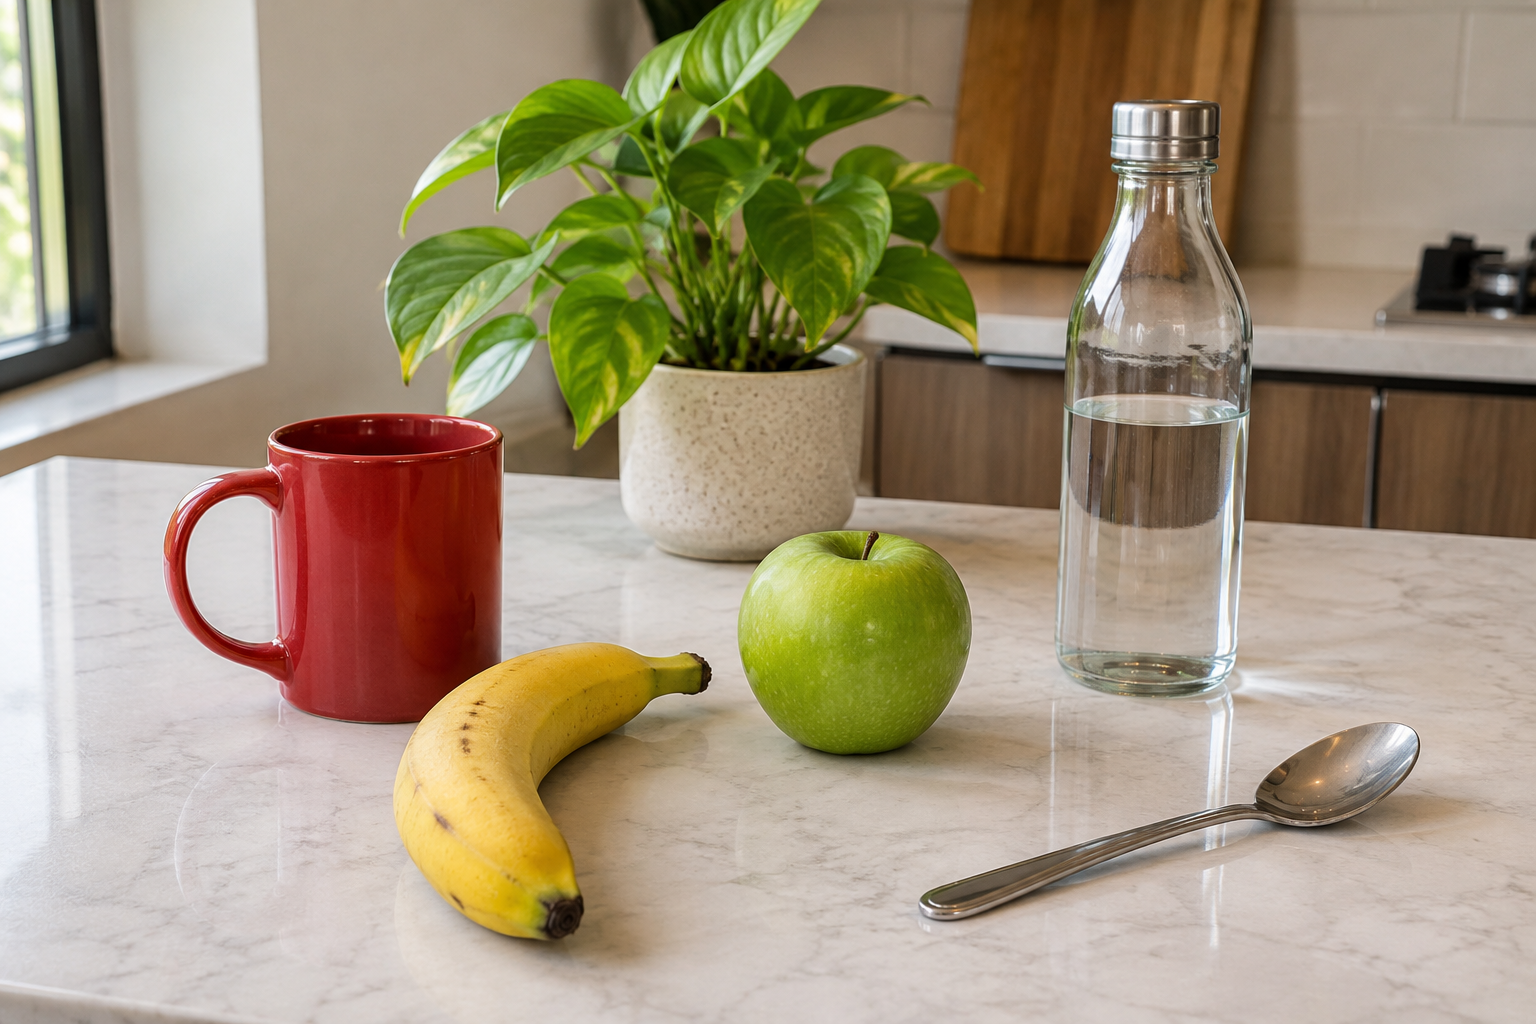

In [7]:
from google.colab import files
from PIL import Image
from IPython.display import display
from pathlib import Path

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload one image to continue.")

image_path = next(iter(uploaded.keys()))
image = Image.open(image_path).convert("RGB")

print("Image:", image_path)
print("Size:", image.size)
display(image)


### 6. Create a reusable VLM question function

Qwen3-VL accepts a conversation containing image and text content. The helper below prepares the visual inputs, applies the chat template, and generates a response.


In [8]:
from qwen_vl_utils import process_vision_info

def ask_vlm(image_path, question, max_new_tokens=256):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image_path},
                {"type": "text", "text": question},
            ],
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )

    # Remove the prompt tokens so only the newly generated answer is decoded.
    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
    ]

    answer = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    return answer.strip()

print("VLM helper is ready.")


VLM helper is ready.


### 7. First VQA experiment

Ask the model a question that can be answered from the uploaded image. Avoid questions that require hidden context or guessing.


In [9]:
question = "Describe the main objects in this image and where they are located."
answer = ask_vlm(image_path, question)

print("Question:", question)
print("\nVLM answer:\n", answer)


Question: Describe the main objects in this image and where they are located.

VLM answer:
 Based on the image provided, here is a description of the main objects and their locations:

The scene is a well-lit, modern kitchen countertop, likely made of white marble or a similar stone with subtle gray veining. The objects are arranged in a casual, inviting composition.

**Main Objects and Their Locations:**

1.  **Red Mug:** Located on the left side of the countertop. It is a glossy, vibrant red ceramic mug with a matching handle. It is positioned in the foreground, slightly to the left.

2.  **Banana:** Situated in the center of the foreground, just to the right of the red mug. It is a ripe, yellow banana with a few small brown spots, lying horizontally.

3.  **Green Apple:** Positioned near the center of the image, slightly to the right of the banana. It is a smooth, shiny, bright green apple with a small brown stem.

4.  **Glass Water Bottle:** Located on the right side of the counter

### 8. Ask a more specific question

Try a question that checks a visible attribute, count, or relationship. The model may still make mistakes, so compare its answer with the image.


In [10]:
question_2 = "What are three details you can directly observe in this image?"
answer_2 = ask_vlm(image_path, question_2)

print("Question:", question_2)
print("\nVLM answer:\n", answer_2)


Question: What are three details you can directly observe in this image?

VLM answer:
 Here are three direct observations from the image:

1. **A red ceramic mug** is positioned on the left side of the countertop, with a glossy finish and a handle.

2. **A clear glass water bottle** with a silver metal cap stands on the right, containing about half a cup of water.

3. **A ripe yellow banana** and a **bright green apple** are placed in the center of the counter, near each other.


### 9. Optional: test a Module 4 invoice or receipt

If you have a **non-sensitive** invoice image from Module 4, upload it in the cell below. Ask for a few specific fields.

Saving Gemini_Generated_Image_yxsgn3yxsgn3yxsg.png to Gemini_Generated_Image_yxsgn3yxsgn3yxsg.png


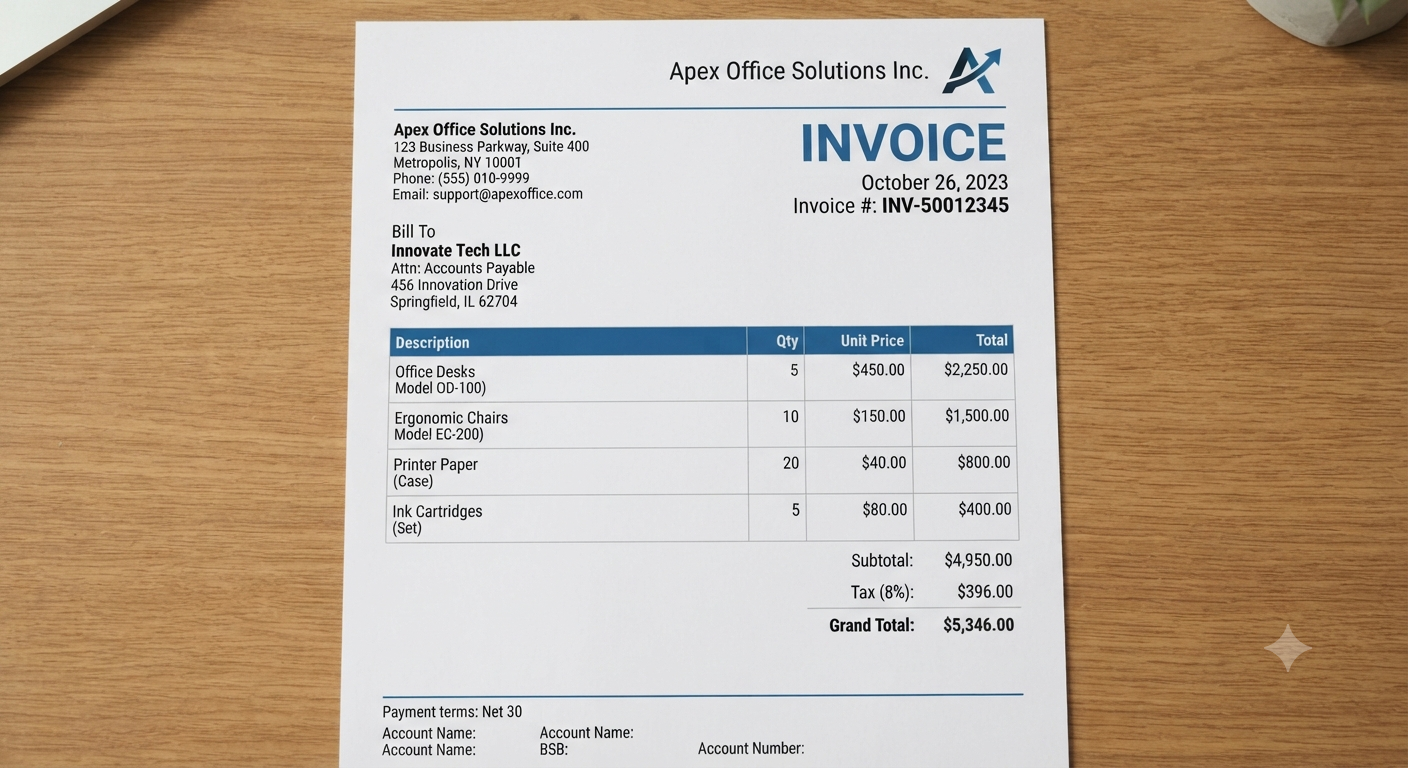

VLM extraction attempt:
 Invoice number: INV-50012345
Invoice date: October 26, 2023
Supplier name: Apex Office Solutions Inc.
Grand total: $5,346.00


In [13]:
# Optional: upload a non-sensitive invoice/receipt image
invoice_upload = files.upload()

if invoice_upload:
    invoice_path = next(iter(invoice_upload.keys()))
    display(Image.open(invoice_path).convert("RGB"))

    invoice_question = (
        "Read the invoice number, invoice date, supplier name, and grand total. "
        "If a value is not clearly visible, say 'not readable' instead of guessing."
    )
    invoice_answer = ask_vlm(invoice_path, invoice_question, max_new_tokens=300)

    print("VLM extraction attempt:\n", invoice_answer)
else:
    print("No invoice uploaded; optional experiment skipped.")


In [14]:
import json
from datetime import datetime

day1_record = {
    "module": 5,
    "day": 1,
    "model": MODEL_ID,
    "image_filename": Path(image_path).name,
    "experiments": [
        {"question": question, "answer": answer},
        {"question": question_2, "answer": answer_2},
    ],
    "created_at": datetime.now().isoformat(timespec="seconds"),
}

if "invoice_path" in globals() and "invoice_answer" in globals():
    day1_record["invoice_experiment"] = {
        "image_filename": Path(invoice_path).name,
        "answer": invoice_answer,
        "note": "Unverified model output; compare with the source image."
    }

output_path = Path("day1_vlm_results.json")
output_path.write_text(json.dumps(day1_record, indent=2, ensure_ascii=False), encoding="utf-8")

print("Saved:", output_path.resolve())


Saved: /content/day1_vlm_results.json
